### 🎯 프로젝트 **목표**

- 이번 과제는 단순히 모델을 구현하는 데서 끝나는 것이 아니라, **기존 Baseline 모델의 한계를 스스로 파악하고 더 나은 방향으로 개선해보는 과정 자체**를 경험하는 데 목적이 있습니다.
- 다양한 실험과 비교를 통해, 하나의 정답을 찾기보다 **문제를 정의하고 가설을 세우고 검증하는 문제 해결 과정**을 직접 연습해보는 것이 중요합니다.
- 이번 과제는 여러분이 지금까지 배운 내용을 바탕으로 진행되지만, **필요하다면 배우지 않은 내용도 스스로 찾아보고 적용해보는 경험**까지 포함합니다.
- 성능 수치만 높이는 것이 아니라, **왜 이런 전략을 선택했는지, 어떤 실험이 효과가 있었는지, 어떤 실패를 통해 무엇을 배웠는지**까지 함께 정리해보며 한 단계 더 성장해보는 것을 목표로 합니다.
- 익숙한 방법만 반복하는 것이 아니라, 새로운 방법을 시도해보며 스스로 탐색하는 과정도 중요한 학습입니다.

# Mission1. 문제 해결 전략 수립 (Flow Planning)

## 1. 문제 정의
- **과제**: 흉부 X-ray 영상을 정상(0)과 폐렴(1)으로 구분하는 이진 분류
- **데이터**
    - train: 5,216장 (정상 1,341장 26%, 폐렴 3,875장 74%) → 클래스 불균형
    - test: 624장, 정답(label) 없음 → 예측 결과를 `sample_submission.csv` 형식으로 제출
- **임상적 의미**: 폐렴을 놓치는 위음성이 정상을 폐렴으로 보는 위양성보다 위험하다.
  따라서 Accuracy와 함께 Recall(민감도)과 Specificity(특이도)를 확인해야 한다.
- **목표**: 단순한 CNN으로 Baseline을 만들고, 한계를 진단한 뒤 개선 방향을 찾는다.

## 2. 전체 흐름
1) **라이브러리 호출, 경로 지정**
2) **데이터 확인**: train/test CSV, 이미지 크기와 색 형식, 라벨 분포, 샘플 이미지
3) **이미지 전처리** (`tf`)
    - 흑백 변환 → 128×128 크기로 조정 → 텐서로 변환 (픽셀값 0~1)
4) **데이터셋 구성**
    - `TrainCSV`: train.csv를 읽어 (이미지, 라벨) 반환
    - `TestCSV`: test.csv를 읽어 이미지만 반환 (라벨 없음)
    - DataLoader: batch 32, 학습은 섞고(shuffle=True), 테스트는 제출 순서 유지(shuffle=False)
5) **Baseline 모델: SimpleCNN**
    - Conv(1→16) → ReLU → MaxPool : (1,128,128) → (16,64,64)
    - Conv(16→32) → ReLU → MaxPool : → (32,32,32)
    - Flatten → Linear(32×32×32 → 2) : 정상, 폐렴 점수 출력
6) **학습 준비**
    - 장치: cuda → mps(Mac GPU) → cpu 순서로 선택
    - seed 고정(42)으로 가중치 초기값 재현
    - 손실함수: CrossEntropyLoss / 최적화: Adam(lr=0.001)
7) **학습**: 10 epoch, epoch별 평균 loss 기록 및 학습 곡선
8) **성능 확인 및 예측**: 학습 데이터 기준 지표, 혼동행렬, ROC 곡선 / test 이미지마다 두 점수 중 큰 쪽(argmax)을 0/1로 판정
9) **제출 파일 생성**: `baseline_submit.csv`
10) **다음 단계 (한계 진단 → 개선)**
    - 검증 데이터 분리(층화 분할)로 Accuracy, 민감도, 특이도, AUC 확인
    - test 이미지는 원본 크기(직사각형)라 Resize 시 찌그러짐 → 비율 유지 리사이즈 검토
    - 불균형 보정, 데이터 증강, ResNet50 전이학습 등 개선 실험


In [1]:
# 라이브러리 호출

import os, pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# 성능 시각화
from sklearn import metrics
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'AppleGothic'     # Mac 한글 폰트
plt.rcParams['axes.unicode_minus'] = False

In [2]:
# 파일 경로 지정
BASE_DIR = "/Users/mac/Desktop/deep_learning/chest_xray"

데이터 크기: (5216, 2)
        file_name  label
0  train_0001.png      0
1  train_0002.png      0
2  train_0003.png      0
3  train_0004.png      0
4  train_0005.png      0
결측치:
 file_name    0
label        0
dtype: int64
중복 파일명: 0
라벨 분포:
 label
1    3875
0    1341
Name: count, dtype: int64
라벨 비율:
 label
1    0.74
0    0.26
Name: proportion, dtype: float64
이미지 파일 수: 5216
CSV-폴더 불일치 파일 수: 0
배열 형태: (224, 224) / 자료형: uint8 / 픽셀값 범위: 0 ~ 250
(크기, 색 형식)별 개수:
 ((224, 224), L)    5216
Name: count, dtype: int64


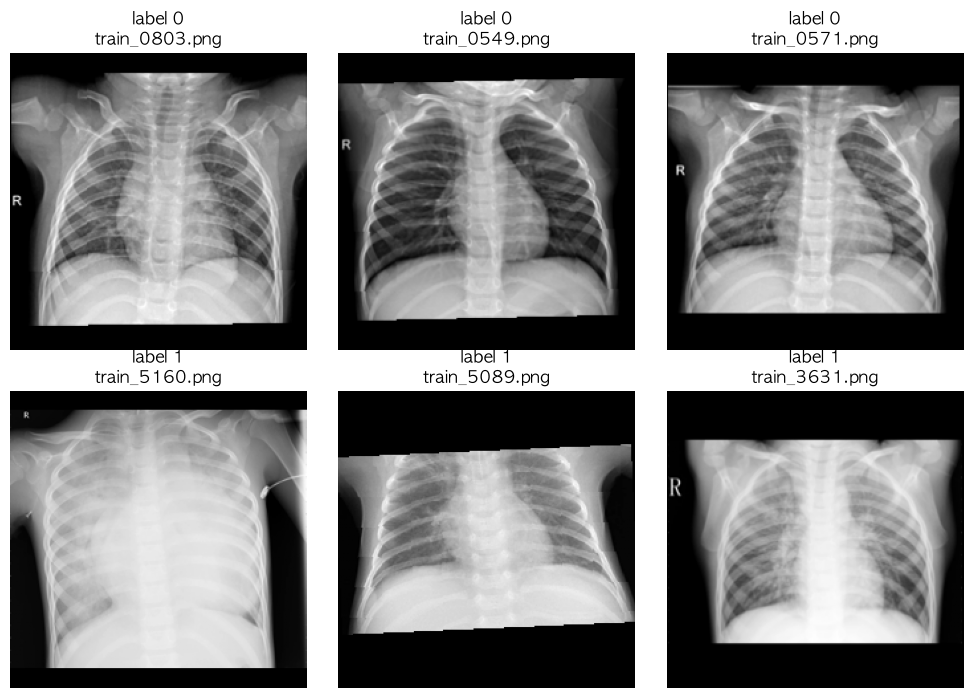

test.csv: (624, 1) ['file_name']
sample_submission.csv: (624, 2) ['file_name', 'label']
test 이미지 수: 624
CSV-폴더 불일치 파일 수: 0
서로 다른 (크기, 색 형식) 종류 수: 598
((1112, 736), L)    3
((1088, 576), L)    2
((1368, 904), L)    2
((1112, 600), L)    2
((1232, 888), L)    2
Name: count, dtype: int64


In [3]:
# 데이터 확인

# 1) train CSV 확인
df = pd.read_csv(os.path.join(BASE_DIR, "train.csv"))
print("데이터 크기:", df.shape)
print(df.head())
print("결측치:\n", df.isnull().sum())
print("중복 파일명:", df["file_name"].duplicated().sum())
print("라벨 분포:\n", df["label"].value_counts())
print("라벨 비율:\n", df["label"].value_counts(normalize=True).round(2))

# CSV와 이미지 폴더 일치 확인
train_files = [f for f in os.listdir(os.path.join(BASE_DIR, "train")) if f.endswith(".png")]
print("이미지 파일 수:", len(train_files))
print("CSV-폴더 불일치 파일 수:", len(set(df["file_name"]) ^ set(train_files)))

# 2) train 이미지 확인
df["image_path"] = [os.path.join(BASE_DIR, "train", f) for f in df["file_name"]]

# 샘플 1장: 숫자 배열로 확인
sample = np.array(Image.open(df["image_path"][0]))
print("배열 형태:", sample.shape, "/ 자료형:", sample.dtype,
      "/ 픽셀값 범위:", sample.min(), "~", sample.max())

# 전체 이미지: 크기와 색 형식
train_info = []
for path in df["image_path"]:
    with Image.open(path) as im:
        train_info.append((im.size, im.mode))
print("(크기, 색 형식)별 개수:\n", pd.Series(train_info).value_counts())

# 라벨별 샘플 이미지 비교 (윗줄: 정상 0, 아랫줄: 폐렴 1)
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for row, label in enumerate([0, 1]):
    paths = df[df["label"] == label]["image_path"].sample(3, random_state=42)
    for col, path in enumerate(paths):
        axes[row, col].imshow(Image.open(path), cmap="gray")
        axes[row, col].set_title(f"label {label}\n{os.path.basename(path)}")
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

# 3) test 데이터 확인
test_df   = pd.read_csv(os.path.join(BASE_DIR, "test.csv"))
submit_df = pd.read_csv(os.path.join(BASE_DIR, "sample_submission.csv"))
print("test.csv:", test_df.shape, list(test_df.columns))
print("sample_submission.csv:", submit_df.shape, list(submit_df.columns))

test_files = [f for f in os.listdir(os.path.join(BASE_DIR, "test")) if f.endswith(".png")]
print("test 이미지 수:", len(test_files))
print("CSV-폴더 불일치 파일 수:", len(set(test_df["file_name"]) ^ set(test_files)))

# test 이미지 크기, 색 형식 (train과 같은지)
test_info = []
for f in test_df["file_name"]:
    with Image.open(os.path.join(BASE_DIR, "test", f)) as im:
        test_info.append((im.size, im.mode))
test_info = pd.Series(test_info)
print("서로 다른 (크기, 색 형식) 종류 수:", test_info.nunique())
print(test_info.value_counts().head())

### 데이터 확인 결과

1) train CSV
- 5,216개, 2개 컬럼 (file_name, label), 결측치와 중복 없음
- label: 0(정상) 1,341개(26%), 1(폐렴) 3,875개(74%) → 불균형
- CSV와 이미지 파일이 정확히 일치

2) train 이미지
- 전체 224×224, 흑백(L, 1채널), uint8 (픽셀값 0~255, 0: 검정, 255: 흰색)
- 라벨 1(폐렴) 영상에서 폐야의 음영 증가 확인
- 특이 사항: 가장자리 검은 여백, 일부 회전된 영상, R 표시와 전극선 등 이물질

3) test 데이터
- 624개, file_name만 있음 (label 없음)
- 제출 양식: file_name, label(0 또는 1)
- test 이미지는 224×224가 아니라 크기가 제각각 (train만 미리 224로 맞춰져 있음)

4) 시사점
- 이미지 크기가 서로 달라 모델에 넣기 전 같은 크기로 맞춰야 함 → Baseline은 128×128로 Resize
- 픽셀값 0~255 → ToTensor로 0~1 스케일링
- 클래스 불균형 → Accuracy만으로 판단하기 어려워 민감도, 특이도를 함께 확인해야 함
- train과 test의 이미지 형태가 달라, Resize 시 test 이미지가 찌그러질 수 있음

In [4]:
# 이미지 전처리
# 이미지를 흑백으로 처리하고, 128*128 크기로 맞춘 뒤 텐서로 변환
tf = transforms.Compose([
    transforms.Grayscale(),
    transforms.Resize((128,128)),
    transforms.ToTensor()
])

In [5]:
# 학습 데이터셋 만들기 (이미지, 라벨) 반환
class TrainCSV(Dataset):
    def __init__(self, csv_path, root_dir="train"):
        df = pd.read_csv(csv_path)
        self.files = df["file_name"].tolist()
        self.labels = df["label"].astype(int).tolist()
        self.root, self.tf = root_dir, tf
    def __len__(self): return len(self.files)
    def __getitem__(self, i):
        img = Image.open(os.path.join(self.root, self.files[i])).convert("L")
        x = self.tf(img)
        y = self.labels[i]
        return x, y

In [6]:
# 테스트 데이터셋 만들기: 이미지만 반환 (라벨없음)
class TestCSV(Dataset):
    def __init__(self, csv_path, root_dir="test"):
        df = pd.read_csv(csv_path)
        self.files = df["file_name"].tolist()
        self.root, self.tf = root_dir, tf
    def __len__(self): return len(self.files)
    def __getitem__(self, i):
        img = Image.open(os.path.join(self.root, self.files[i])).convert("L")
        x = self.tf(img)
        return x

In [7]:
# 데이터로더 생성

train_ds = TrainCSV(os.path.join(BASE_DIR, "train.csv"), root_dir=os.path.join(BASE_DIR, "train"))
test_ds = TestCSV(os.path.join(BASE_DIR, "test.csv"), root_dir=os.path.join(BASE_DIR, "test"))

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

print(len(train_ds), len(test_ds))   # train: 5216개, test: 624개

5216 624


In [8]:
# SimpleCNN 모델 
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv= nn.Sequential(
            # (1, 128, 128) → (16,64,64)
            nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            # (16,64,64) → (32,32,32)
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2)
        )
         # 출력 2개: 정상, 폐렴
        self.fc = nn.Sequential(nn.Flatten(), nn.Linear(32*32*32, 2))
    def forward(self, x): return self.fc(self.conv(x))

In [9]:
# 학습준비
# 장치 준비 (cuda: NVIDIA GPU, mps: Mac GPU, 없으면 cpu)
device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
# 이진 분류 손실함수 (모델과 optimizer는 학습 셀에서 seed 고정 후 생성)
criterion = nn.CrossEntropyLoss()

Epoch 1 | loss 0.2809
Epoch 2 | loss 0.1389
Epoch 3 | loss 0.1145
Epoch 4 | loss 0.0999
Epoch 5 | loss 0.0839
Epoch 6 | loss 0.0771
Epoch 7 | loss 0.0692
Epoch 8 | loss 0.0640
Epoch 9 | loss 0.0583
Epoch 10 | loss 0.0499


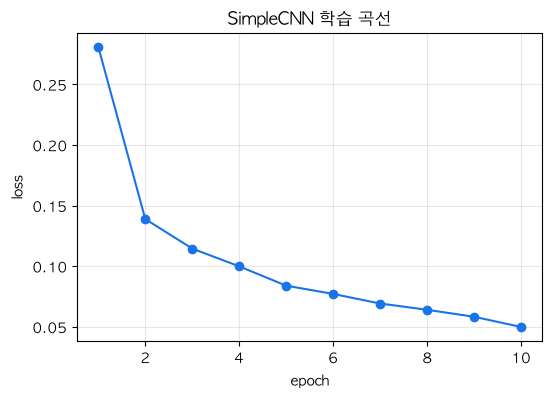

In [10]:
# 학습 
torch.manual_seed(42)
model = SimpleCNN().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)

train_losses = []                                   # 추가 ①: loss를 담을 리스트
for epoch in range(10):
    model.train(); running = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = criterion(logits, y)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        running += loss.item() * x.size(0)
    epoch_loss = running / len(train_loader.dataset)
    train_losses.append(epoch_loss)                 # 추가 ②: epoch마다 저장
    print(f"Epoch {epoch+1} | loss {epoch_loss:.4f}")

# 학습 곡선
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(train_losses) + 1), train_losses, marker='o', color='#1A73E8')
plt.xlabel('epoch'); plt.ylabel('loss')
plt.title('SimpleCNN 학습 곡선')
plt.grid(alpha=0.3)
plt.show()

Accuracy: 0.9850
민감도     : 0.9920
특이도     : 0.9650
F1      : 0.9900
AUC     : 0.9990


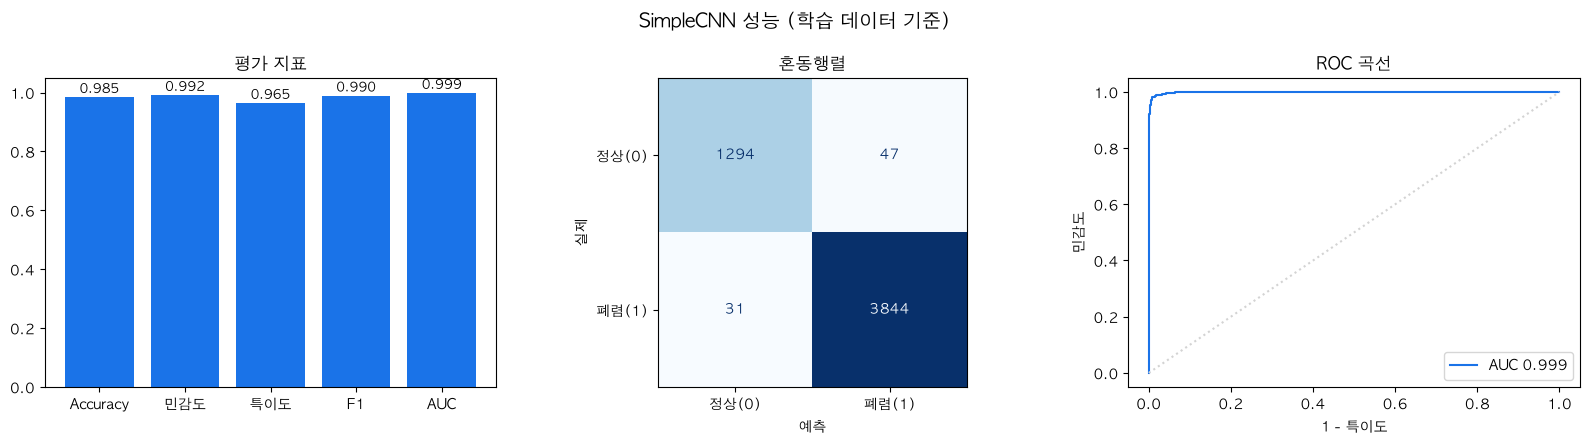

In [11]:
# 학습 데이터 예측
model.eval()
y_true, y_pred, y_prob = [], [], []
with torch.no_grad():
    for x, y in train_loader:
        logits = model(x.to(device))
        y_pred.extend(logits.argmax(1).cpu().numpy())                 # 0/1 판정
        y_prob.extend(torch.softmax(logits, 1)[:, 1].cpu().numpy())   # 폐렴 확률
        y_true.extend(y.numpy())

tn, fp, fn, tp = metrics.confusion_matrix(y_true, y_pred).ravel()
scores = {
    'Accuracy': metrics.accuracy_score(y_true, y_pred),
    '민감도'   : tp / (tp + fn),
    '특이도'   : tn / (tn + fp),
    'F1'      : metrics.f1_score(y_true, y_pred),
    'AUC'     : metrics.roc_auc_score(y_true, y_prob),
}
for k, v in scores.items():
    print(f"{k:8s}: {v:.4f}")

    # 지표, 혼동행렬, ROC 곡선
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
fig.suptitle('SimpleCNN 성능 (학습 데이터 기준)', fontsize=14)

# ① 평가 지표
bars = axes[0].bar(scores.keys(), scores.values(), color='#1A73E8')
axes[0].bar_label(bars, fmt='%.3f', fontsize=9)
axes[0].set_ylim(0, 1.05)
axes[0].set_title('평가 지표')

# ② 혼동행렬
metrics.ConfusionMatrixDisplay(
    metrics.confusion_matrix(y_true, y_pred),
    display_labels=['정상(0)', '폐렴(1)']
).plot(ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_xlabel('예측'); axes[1].set_ylabel('실제')
axes[1].set_title('혼동행렬')

# ③ ROC 곡선
fpr, tpr, _ = metrics.roc_curve(y_true, y_prob)
axes[2].plot(fpr, tpr, color='#1A73E8', label=f"AUC {scores['AUC']:.3f}")
axes[2].plot([0, 1], [0, 1], color='lightgray', linestyle=':')
axes[2].set_xlabel('1 - 특이도'); axes[2].set_ylabel('민감도')
axes[2].set_title('ROC 곡선'); axes[2].legend(loc='lower right')

plt.tight_layout(); plt.show()

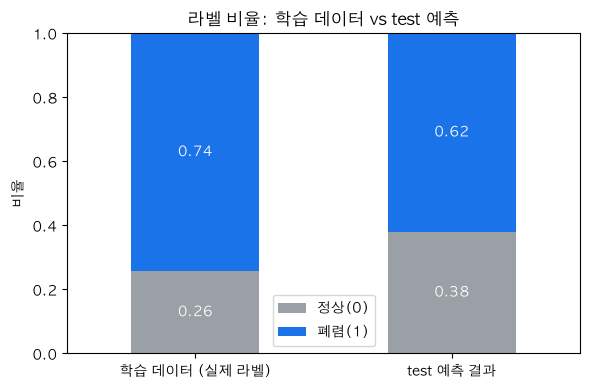

In [12]:
# SimpleCNN test 예측
model.eval()
cnn_test_preds = []
with torch.no_grad():
    for x in test_loader:
        cnn_test_preds.extend(model(x.to(device)).argmax(1).cpu().numpy())

train_ratio = pd.Series(train_ds.labels).value_counts(normalize=True).sort_index()
test_ratio  = pd.Series(cnn_test_preds).value_counts(normalize=True).reindex([0, 1], fill_value=0)

ratio_df = pd.DataFrame({'학습 데이터 (실제 라벨)': train_ratio,
                         'test 예측 결과': test_ratio})
ratio_df.index = ['정상(0)', '폐렴(1)']

ax = ratio_df.T.plot(kind='bar', stacked=True, figsize=(6, 4),
                     color=['#9AA0A6', '#1A73E8'])
ax.set_ylabel('비율'); ax.set_ylim(0, 1)
ax.set_title('라벨 비율: 학습 데이터 vs test 예측')
ax.tick_params(axis='x', rotation=0)
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', label_type='center', color='white')
plt.tight_layout(); plt.show()

In [13]:
# 파일 제출
submission = pd.read_csv(os.path.join(BASE_DIR, "sample_submission.csv"))
submission["label"] = cnn_test_preds    # 위 셀의 SimpleCNN test 예측

submission.to_csv("baseline_submit.csv", index=False)
print(submission["label"].value_counts())

label
1    387
0    237
Name: count, dtype: int64


# Mission 2. 문제 해결 전략 수립 (Flow Planning)

## 1. 문제 정의
### 1) 과제
- 흉부 X-ray 영상을 정상(0)과 폐렴(1)으로 구분하는 이진 분류
- train 5,216장 (정상 26%, 폐렴 74%), test 624장 (정답 없음, 0/1로 예측해 제출)
- 임상적으로 폐렴을 놓치는 위음성이 더 위험하므로, Accuracy와 함께 민감도와 특이도를 확인한다.

### 2) Baseline(SimpleCNN)에서 확인한 한계
| 한계 | 근거 | 문제점 |
|---|---|---|
| 성능을 검증할 수 없음 | train 전체로 학습, 검증 데이터 없음, train loss만 확인(0.28 → 0.05) | 처음 보는 데이터에서의 성능을 알 수 없음 |
| 과적합 가능성 | loss가 계속 감소, Flatten 뒤 파라미터가 약 33만 개로 대부분 마지막 층에 집중 | 학습 데이터를 외웠을 가능성 확인 필요 |
| train과 test 이미지 형태 차이 | train은 224*224로 미리 가공(비율 유지 + 검은 여백), test는 원본 크기(직사각형) | Resize(128,128)가 test 이미지를 찌그러뜨려 학습 때와 다른 모양으로 예측 |
| 클래스 불균형 미보정 | 폐렴 74% | 모델이 폐렴 쪽으로 치우쳐 정상을 폐렴으로 오진할 위험 (특이도 저하) |
| 특징 추출 능력의 한계 | Conv 층 2개, 랜덤 초기값에서 학습 | 미세한 폐 음영 차이를 학습하기에 모델이 단순함 |

### 3) 해결할 문제
- 같은 기준으로 성능을 비교할 수 있는 **평가 체계**를 만든다.
- train과 test의 **입력 형태를 일치**시킨다.
- 적은 데이터에도 좋은 특징을 쓸 수 있도록 **사전학습 모델 ResNet50**을 적용하고, 2개 이상의 개선 전략으로 성능을 높인다.

## 2. 전체 흐름

1) **평가 체계 만들기** → Mission 3
    - train을 학습:검증 = 8:2로 층화 분할 (라벨 비율 유지, seed 고정)
    - 평가 지표: Accuracy(주요지표), 민감도, 특이도, F1, AUC, 혼동행렬
    - SimpleCNN을 이 기준으로 다시 평가해 **Baseline 점수**로 기록

2) **입력 형태 일치** → Mission 3
    - 비율을 유지한 채 줄이고 남는 곳은 검은 여백으로 채우는 Resize 적용
    - train과 test가 같은 모양으로 모델에 들어가도록 함

3) **ResNet50 전이학습** (완료)
    - ImageNet 사전학습 가중치 사용, 1채널 -> 3채널 복제, ImageNet 기준 정규화
    - 백본 고정, 분류층(fc)만 학습 -> 데이터가 적어 과적합 방지
    - Baseline과 같은 검증 데이터, 손실함수, 옵티마이저로 비교

4) **개선 실험 (한 번에 하나씩 변경)** → Mission 4
    - Fine-tuning: ResNet50 뒤를 낮은 학습률로 함께 학습
    - 불균형 보정: CrossEntropyLoss에 Class weight 적용 -> 특이도 개선 확인
    - 데이터 증강: 약한 회전, 밝기 조절 (좌우 반전은 장기의 위치가 바뀌어 제외)
    - 필요시 threshold 조정으로 민감도와 특이도 균형 맞추기

5) **결과 비교 해석** → Mission 5
    - 모든 실험을 같은 검증 데이터로 비교표 작성
    - 학습 곡선(과적합 여부), Grad-CAM(폐 영역을 보고 판단하는지) 확인
    - 효과가 없었던 실험도 원인과 함께 기록

6) **최종 모델 선정과 제출** → Mission 5
    - 검증 성능이 가장 좋은 모델로 test 예측 -> 제출 파일 생성
    - kernel 재시작 후 처음부터 실행해 같은 결과가 나오는지 재현성 확인

In [14]:
# 추가 라이브러리
from torchvision import models # 사전학습 모델

In [15]:
# ResNet50 입력 형식에 맞춘 전처리
tf_resnet = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),     # 흑백 -> 같은 값 3채널로 복제
    transforms.Resize((224, 224)),                   # ResNet50 표준 입력 크기
    transforms.ToTensor(),                           # 픽셀값 0~1
    transforms.Normalize(mean=[0.485, 0.456, 0.406], # ImageNet 평균
                         std=[0.229, 0.224, 0.225])  # ImageNet 표준편차
])

In [16]:
# 데이터로더
# 데이터셋은 Baseline과 같은 클래스를 쓰고, 전처리만 ResNet용으로 변경
train_ds_r = TrainCSV(os.path.join(BASE_DIR, "train.csv"), root_dir=os.path.join(BASE_DIR, "train"))
test_ds_r = TestCSV(os.path.join(BASE_DIR, "test.csv"), root_dir=os.path.join(BASE_DIR, "test"))
train_ds_r.tf = tf_resnet
test_ds_r.tf = tf_resnet

train_loader_r = DataLoader(train_ds_r, batch_size=32, shuffle=True)
test_loader_r = DataLoader(test_ds_r, batch_size=32, shuffle=False)

x, y = next(iter(train_loader_r))
print(x.shape)     # torch.size([32, 3, 224, 224]) → 3채널, 224 확인

torch.Size([32, 3, 224, 224])


In [17]:
# ResNet50 모델 구조 확인 (학습 파라미터 수 확인용, 실제 학습은 아래 셀에서 새로 생성)
torch.manual_seed(42)
resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)  # ImageNet 사전학습 가중치

# 백본 고정: 사전학습된 가중치는 학습하지 않음
for param in resnet.parameters():
    param.requires_grad = False

# 분류층 교체: 1000개(ImageNet 클래스) → 2개(정상, 폐렴), 분류층만 학습
resnet.fc = nn.Linear(resnet.fc.in_features, 2)
resnet = resnet.to(device)

trainable = sum(p.numel() for p in resnet.parameters() if p.requires_grad)
total = sum(p.numel() for p in resnet.parameters())
print(f"학습 파라미터: {trainable:,} / 전체 {total:,}")

학습 파라미터: 4,098 / 전체 23,512,130


Epoch 1 | loss 0.2065
Epoch 2 | loss 0.1599
Epoch 3 | loss 0.1458
Epoch 4 | loss 0.1335
Epoch 5 | loss 0.1332
Epoch 6 | loss 0.1226
Epoch 7 | loss 0.1248
Epoch 8 | loss 0.1298
Epoch 9 | loss 0.1257
Epoch 10 | loss 0.1151


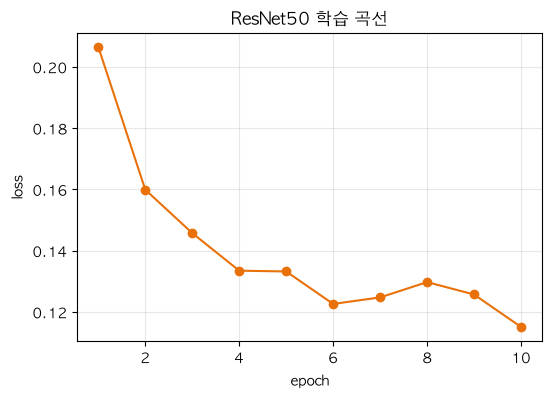

In [18]:
# ResNet50 학습 (loss 기록 추가)
torch.manual_seed(42)
resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
for param in resnet.parameters():
    param.requires_grad = False                      # 백본 고정
resnet.fc = nn.Linear(resnet.fc.in_features, 2)      # 분류층만 학습
resnet = resnet.to(device)
optimizer = optim.Adam(resnet.fc.parameters(), lr=0.001)

res_train_losses = []                                # loss를 담을 리스트
for epoch in range(10):
    resnet.train(); running = 0.0
    for x, y in train_loader_r:
        x, y = x.to(device), y.to(device)
        logits = resnet(x)
        loss = criterion(logits, y)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        running += loss.item() * x.size(0)
    epoch_loss = running / len(train_loader_r.dataset)
    res_train_losses.append(epoch_loss)              # epoch마다 저장
    print(f"Epoch {epoch+1} | loss {epoch_loss:.4f}")

# 학습 곡선
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(res_train_losses) + 1), res_train_losses, marker='o', color='#E8710A')
plt.xlabel('epoch'); plt.ylabel('loss')
plt.title('ResNet50 학습 곡선')
plt.grid(alpha=0.3)
plt.show()

Accuracy: 0.9688
민감도     : 0.9881
특이도     : 0.9128
F1      : 0.9792
AUC     : 0.9954


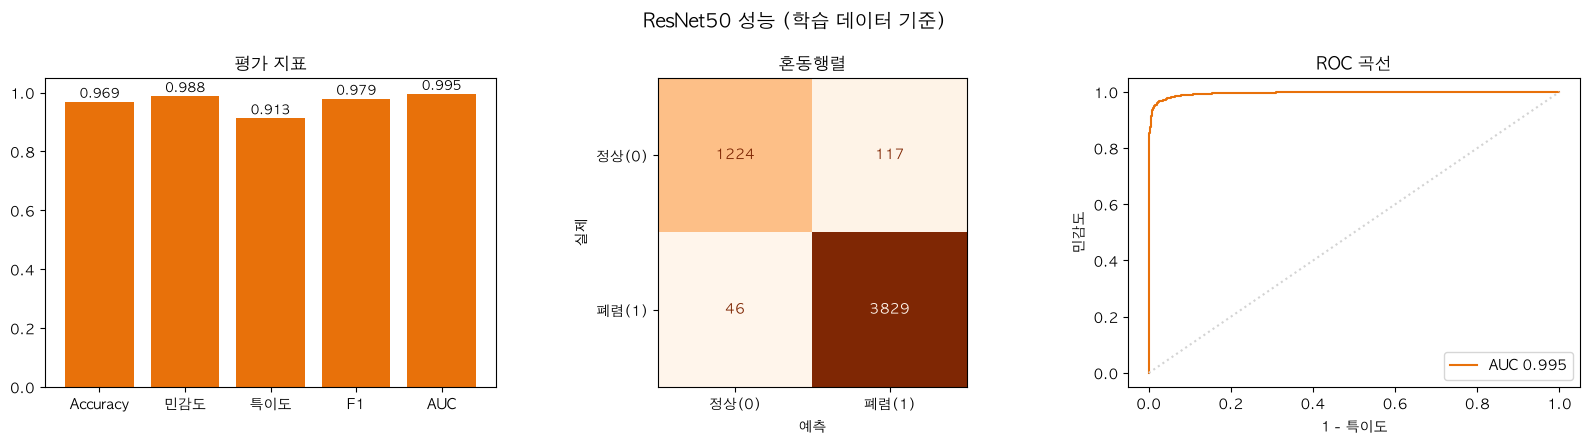

In [19]:
# 학습 데이터 예측
resnet.eval()
res_true, res_pred, res_prob = [], [], []
with torch.no_grad():
    for x, y in train_loader_r:
        logits = resnet(x.to(device))
        res_pred.extend(logits.argmax(1).cpu().numpy())                 # 0/1 판정
        res_prob.extend(torch.softmax(logits, 1)[:, 1].cpu().numpy())   # 폐렴 확률
        res_true.extend(y.numpy())

tn, fp, fn, tp = metrics.confusion_matrix(res_true, res_pred).ravel()
res_scores = {
    'Accuracy': metrics.accuracy_score(res_true, res_pred),
    '민감도'   : tp / (tp + fn),
    '특이도'   : tn / (tn + fp),
    'F1'      : metrics.f1_score(res_true, res_pred),
    'AUC'     : metrics.roc_auc_score(res_true, res_prob),
}
for k, v in res_scores.items():
    print(f"{k:8s}: {v:.4f}")

# 지표, 혼동행렬, ROC 곡선
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
fig.suptitle('ResNet50 성능 (학습 데이터 기준)', fontsize=14)

# ① 평가 지표
bars = axes[0].bar(res_scores.keys(), res_scores.values(), color='#E8710A')
axes[0].bar_label(bars, fmt='%.3f', fontsize=9)
axes[0].set_ylim(0, 1.05)
axes[0].set_title('평가 지표')

# ② 혼동행렬
metrics.ConfusionMatrixDisplay(
    metrics.confusion_matrix(res_true, res_pred),
    display_labels=['정상(0)', '폐렴(1)']
).plot(ax=axes[1], cmap='Oranges', colorbar=False)
axes[1].set_xlabel('예측'); axes[1].set_ylabel('실제')
axes[1].set_title('혼동행렬')

# ③ ROC 곡선
fpr, tpr, _ = metrics.roc_curve(res_true, res_prob)
axes[2].plot(fpr, tpr, color='#E8710A', label=f"AUC {res_scores['AUC']:.3f}")
axes[2].plot([0, 1], [0, 1], color='lightgray', linestyle=':')
axes[2].set_xlabel('1 - 특이도'); axes[2].set_ylabel('민감도')
axes[2].set_title('ROC 곡선'); axes[2].legend(loc='lower right')

plt.tight_layout(); plt.show()

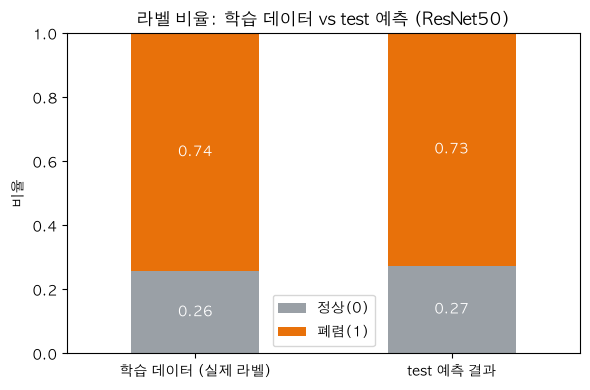

In [20]:
# ResNet50 test 예측
resnet.eval()
res_test_preds = []
with torch.no_grad():
    for x in test_loader_r:
        res_test_preds.extend(resnet(x.to(device)).argmax(1).cpu().numpy())

train_ratio = pd.Series(train_ds_r.labels).value_counts(normalize=True).sort_index()
test_ratio  = pd.Series(res_test_preds).value_counts(normalize=True).reindex([0, 1], fill_value=0)

ratio_df = pd.DataFrame({'학습 데이터 (실제 라벨)': train_ratio,
                         'test 예측 결과': test_ratio})
ratio_df.index = ['정상(0)', '폐렴(1)']

ax = ratio_df.T.plot(kind='bar', stacked=True, figsize=(6, 4),
                     color=['#9AA0A6', '#E8710A'])
ax.set_ylabel('비율'); ax.set_ylim(0, 1)
ax.set_title('라벨 비율: 학습 데이터 vs test 예측 (ResNet50)')
ax.tick_params(axis='x', rotation=0)
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', label_type='center', color='white')
plt.tight_layout(); plt.show()

In [21]:
# 제출 파일
submission = pd.read_csv(os.path.join(BASE_DIR, "sample_submission.csv"))
submission["label"] = res_test_preds
submission.to_csv("resnet_submit.csv", index=False)
print(submission["label"].value_counts())

label
1    453
0    171
Name: count, dtype: int64


### 결과 비교 (학습 데이터 기준)

| 지표 | SimpleCNN | ResNet50 (전이학습) |
|---|---|---|
| Accuracy | 0.985 | 0.969 |
| 민감도 | 0.992 | 0.988 |
| 특이도 | 0.965 | 0.913 |
| F1 | 0.990 | 0.979 |
| AUC | 0.999 | 0.995 |
| test 예측 (정상 : 폐렴) | 237 : 387 | 171 : 453 |

- 두 모델 모두 학습에 쓴 데이터로 평가했기 때문에 실제 일반화 성능은 알 수 없다.
- SimpleCNN의 학습 데이터 점수가 더 높은 것은 전체 파라미터를 학습해 데이터에 더 많이 맞춰졌기 때문일 수 있다 (과적합 가능성).
- ResNet50은 분류층(4,098개)만 학습해 loss가 0.12 근처에서 더 내려가지 않았다.
  ImageNet(일상 사진)에서 배운 특징이 X-ray에 그대로 맞지 않을 가능성이 있다 → Fine-tuning 필요성.
- 두 모델 모두 특이도가 민감도보다 낮고, ResNet50은 test를 폐렴으로 더 많이 예측했다 (73%).
  클래스 불균형(폐렴 74%)의 영향으로 정상을 폐렴으로 오진하는 경향이 있다 → class weight 필요성.
- 다음 단계: 검증 데이터 분리 후 같은 기준으로 두 모델을 다시 비교하고, Fine-tuning과 class weight를 개선 전략으로 적용한다.

# Mission 3. 평가 체계 구축과 입력 형태 일치

## 1. 문제 정의
- **Mission 2에서 확인한 한계**
    - 두 모델 모두 train 전체로 학습하고 같은 데이터로 평가했다 → 처음 보는 데이터에서의 실제 성능을 알 수 없다.
    - train 이미지는 224×224 정사각형(비율 유지 + 검은 여백)으로 미리 가공되어 있고, test 이미지는 원본 크기(직사각형)이다.
      `Resize((128,128))`는 test 이미지를 찌그러뜨려 학습 때와 다른 모양으로 예측하게 만든다.
- **목표**
    1) 모든 모델을 같은 기준으로 비교할 수 있는 **평가 체계**를 만든다.
    2) train과 test의 **입력 형태를 일치**시킨다.

## 2. 전체 흐름
1) **평가 체계**
    - train을 학습 80% : 검증 20%로 층화 분할 (라벨 비율 유지, seed 42) → 모든 실험이 같은 분할 사용
    - 매 epoch 검증 loss를 계산하고, **검증 loss가 가장 낮은 epoch의 모델**로 평가 (과적합 시점 이후 모델 사용 방지)
    - 지표: Accuracy(주 지표), 민감도, 특이도, F1, AUC, 혼동행렬
2) **공통 함수**: 데이터로더 생성, 학습, 예측, 결과 기록/시각화
3) **Baseline 재평가**: SimpleCNN을 학습 데이터(80%)로 다시 학습하고 검증 데이터로 평가 → 이후 모든 실험의 비교 기준
4) **입력 형태 일치**: 비율을 유지한 채 줄이고 남는 곳은 검은 여백으로 채우는 리사이즈
    - train 이미지는 이미 정사각형이라 변화가 없다 → 검증 점수는 바뀌지 않는다.
    - test 이미지에만 영향을 주므로, **test 예측 분포의 변화**로 효과를 확인한다.

In [22]:
# 3-1) 평가 체계 준비
import copy
import torch.nn.functional as F
from torch.utils.data import Subset
from sklearn.model_selection import train_test_split

TRAIN_CSV  = os.path.join(BASE_DIR, "train.csv")
TRAIN_DIR  = os.path.join(BASE_DIR, "train")
TEST_CSV   = os.path.join(BASE_DIR, "test.csv")
TEST_DIR   = os.path.join(BASE_DIR, "test")
SUBMIT_CSV = os.path.join(BASE_DIR, "sample_submission.csv")
EPOCHS = 10                       # 모든 실험에서 동일 (시간이 부족하면 줄여도 됨, 단 모든 실험 동일하게)

# 학습 80% / 검증 20% 층화 분할 (모든 실험이 같은 분할 사용)
labels = pd.read_csv(TRAIN_CSV)["label"].astype(int).tolist()
tr_idx, va_idx = train_test_split(list(range(len(labels))), test_size=0.2,
                                  stratify=labels, random_state=42)
print("학습:", len(tr_idx), "/ 검증:", len(va_idx))
print("학습 라벨 비율:", pd.Series([labels[i] for i in tr_idx]).value_counts(normalize=True).round(3).to_dict())
print("검증 라벨 비율:", pd.Series([labels[i] for i in va_idx]).value_counts(normalize=True).round(3).to_dict())

학습: 4172 / 검증: 1044
학습 라벨 비율: {1: 0.743, 0: 0.257}
검증 라벨 비율: {1: 0.743, 0: 0.257}


In [23]:
# 3-2) 전처리 정의

# 비율 유지 리사이즈: 긴 쪽을 size에 맞춰 줄이고, 남는 곳은 검은 여백으로 채움 (train 이미지와 같은 형태)
def resize_with_padding(img, size):
    img = img.convert("L").copy()
    img.thumbnail((size, size))
    canvas = Image.new("L", (size, size), 0)
    canvas.paste(img, ((size - img.width) // 2, (size - img.height) // 2))
    return canvas

IMAGENET_NORM = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

# SimpleCNN용: 비율 유지 128×128
tf_cnn_pad = transforms.Compose([
    transforms.Lambda(lambda img: resize_with_padding(img, 128)),
    transforms.ToTensor()
])

# ResNet50용: 비율 유지 224×224, 3채널, ImageNet 정규화
tf_res_pad = transforms.Compose([
    transforms.Lambda(lambda img: resize_with_padding(img, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    IMAGENET_NORM
])

# ResNet50 + 데이터 증강용 (학습 데이터에만 사용, Mission 4)
# 좌우 반전은 심장 위치가 바뀌어 해부학적으로 맞지 않아 제외
tf_res_aug = transforms.Compose([
    transforms.Lambda(lambda img: resize_with_padding(img, 224)),
    transforms.RandomRotation(10),                          # ±10도 회전
    transforms.ColorJitter(brightness=0.2, contrast=0.2),   # 밝기, 대비 변화
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    IMAGENET_NORM
])

In [24]:
# 3-3) 공통 함수

def make_test_loader(eval_tf, batch_size=32):
    ds = TestCSV(TEST_CSV, root_dir=TEST_DIR); ds.tf = eval_tf
    return DataLoader(ds, batch_size=batch_size, shuffle=False)

def make_loaders(train_tf, eval_tf, batch_size=32):
    # 학습용과 평가용 데이터셋을 따로 만들어, 증강은 학습 데이터에만 적용되도록 함
    train_full = TrainCSV(TRAIN_CSV, root_dir=TRAIN_DIR); train_full.tf = train_tf
    eval_full  = TrainCSV(TRAIN_CSV, root_dir=TRAIN_DIR); eval_full.tf  = eval_tf
    g = torch.Generator().manual_seed(42)                   # 섞는 순서 고정 (재현성)
    train_loader = DataLoader(Subset(train_full, tr_idx), batch_size=batch_size, shuffle=True, generator=g)
    val_loader   = DataLoader(Subset(eval_full,  va_idx), batch_size=batch_size, shuffle=False)
    return train_loader, val_loader

def train_model(model, train_loader, val_loader, optimizer, loss_fn, epochs=EPOCHS):
    history = {'train': [], 'val': []}
    best_loss = float('inf')
    for epoch in range(epochs):
        # 학습
        model.train(); running = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = loss_fn(model(x), y)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            running += loss.item() * x.size(0)
        history['train'].append(running / len(train_loader.dataset))

        # 검증
        model.eval(); running = 0.0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                running += loss_fn(model(x), y).item() * x.size(0)
        val_loss = running / len(val_loader.dataset)
        history['val'].append(val_loss)

        # 검증 loss가 가장 낮은 시점의 모델 저장
        if val_loss < best_loss:
            best_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            history['best_epoch'] = epoch + 1
        print(f"Epoch {epoch+1:2d} | train loss {history['train'][-1]:.4f} | val loss {val_loss:.4f}")

    model.load_state_dict(best_state)   # 최적 시점의 모델로 되돌리기
    print(f"→ 최적 epoch: {history['best_epoch']} (val loss {best_loss:.4f})")
    return history

def predict(model, loader):
    model.eval()
    y_true, y_pred, y_prob = [], [], []
    with torch.no_grad():
        for x, y in loader:
            logits = model(x.to(device))
            y_pred.extend(logits.argmax(1).cpu().numpy())                 # 0/1 판정
            y_prob.extend(torch.softmax(logits, 1)[:, 1].cpu().numpy())   # 폐렴 확률
            y_true.extend(np.array(y))
    return np.array(y_true), np.array(y_pred), np.array(y_prob)

def predict_test(model, loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for x in loader:
            preds.extend(model(x.to(device)).argmax(1).cpu().numpy())
    return np.array(preds)

def get_scores(y_true, y_pred, y_prob):
    tn, fp, fn, tp = metrics.confusion_matrix(y_true, y_pred).ravel()
    return {'Accuracy': metrics.accuracy_score(y_true, y_pred),
            '민감도'   : tp / (tp + fn),
            '특이도'   : tn / (tn + fp),
            'F1'      : metrics.f1_score(y_true, y_pred),
            'AUC'     : metrics.roc_auc_score(y_true, y_prob)}

# 모든 실험 결과를 모아두는 곳 (Mission 5에서 비교)
results, outputs, histories, trained, eval_tfs = {}, {}, {}, {}, {}

def record(name, model, val_loader, history, eval_tf, color='#1A73E8'):
    y_true, y_pred, y_prob = predict(model, val_loader)
    s = get_scores(y_true, y_pred, y_prob)
    results[name], outputs[name], histories[name] = s, (y_true, y_pred, y_prob), history
    trained[name], eval_tfs[name] = model, eval_tf

    print(f"===== {name} (검증 데이터) =====")
    for k, v in s.items():
        print(f"{k:8s}: {v:.4f}")

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
    fig.suptitle(f'{name} (검증 데이터 기준)', fontsize=13)
    ep = range(1, len(history['train']) + 1)
    axes[0].plot(ep, history['train'], color=color, linestyle='--', label='train loss')
    axes[0].plot(ep, history['val'], color=color, label='val loss')
    axes[0].axvline(history['best_epoch'], color='gray', linestyle=':', label=f"best epoch {history['best_epoch']}")
    axes[0].set_xlabel('epoch'); axes[0].set_title('학습 곡선'); axes[0].legend()
    metrics.ConfusionMatrixDisplay(metrics.confusion_matrix(y_true, y_pred),
                                   display_labels=['정상(0)', '폐렴(1)']).plot(ax=axes[1], cmap='Blues', colorbar=False)
    axes[1].set_xlabel('예측'); axes[1].set_ylabel('실제'); axes[1].set_title('혼동행렬')
    fpr, tpr, _ = metrics.roc_curve(y_true, y_prob)
    axes[2].plot(fpr, tpr, color=color, label=f"AUC {s['AUC']:.3f}")
    axes[2].plot([0, 1], [0, 1], color='lightgray', linestyle=':')
    axes[2].set_xlabel('1 - 특이도'); axes[2].set_ylabel('민감도'); axes[2].set_title('ROC 곡선')
    axes[2].legend(loc='lower right')
    plt.tight_layout(); plt.show()
    return s

Epoch  1 | train loss 0.3137 | val loss 0.1860
Epoch  2 | train loss 0.1631 | val loss 0.1565
Epoch  3 | train loss 0.1229 | val loss 0.1189
Epoch  4 | train loss 0.1006 | val loss 0.1232
Epoch  5 | train loss 0.0898 | val loss 0.1242
Epoch  6 | train loss 0.0920 | val loss 0.1125
Epoch  7 | train loss 0.0785 | val loss 0.1036
Epoch  8 | train loss 0.0682 | val loss 0.0941
Epoch  9 | train loss 0.0721 | val loss 0.0986
Epoch 10 | train loss 0.0556 | val loss 0.0995
→ 최적 epoch: 8 (val loss 0.0941)


/var/folders/bd/mmvg00pj33n_skzfx2sf9tt00000gn/T/ipykernel_39915/1508372954.py:57: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  y_true.extend(np.array(y))


===== SimpleCNN (Baseline) (검증 데이터) =====
Accuracy: 0.9617
민감도     : 0.9601
특이도     : 0.9664
F1      : 0.9739
AUC     : 0.9933


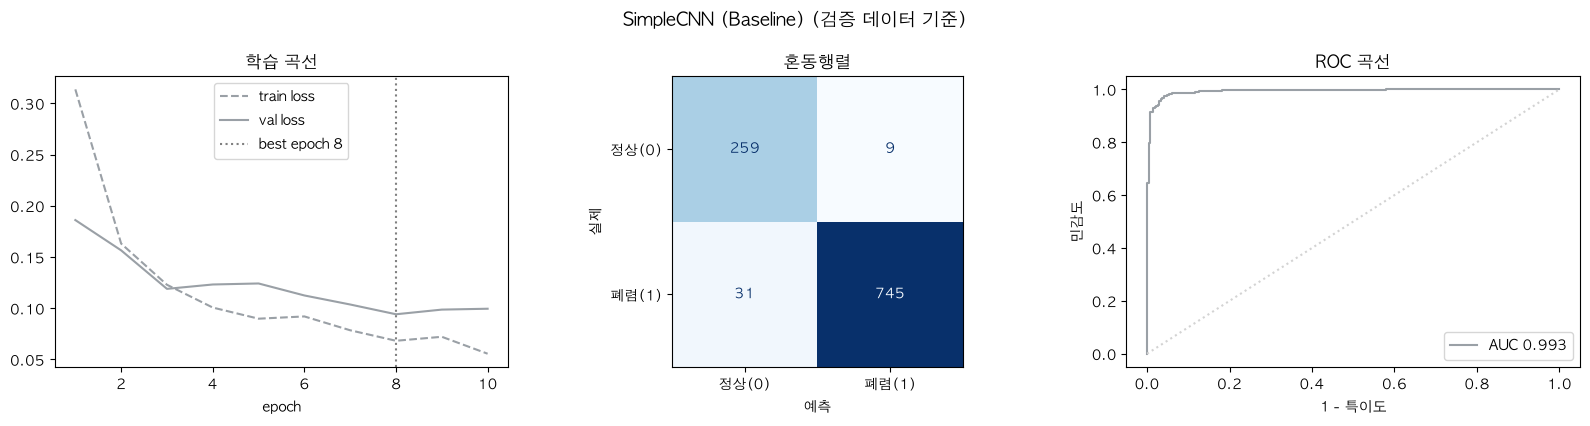

{'Accuracy': 0.9616858237547893,
 '민감도': np.float64(0.9600515463917526),
 '특이도': np.float64(0.9664179104477612),
 'F1': 0.9738562091503268,
 'AUC': 0.9932970456993383}

In [25]:
# 3-4) Baseline 재평가: SimpleCNN (학습 80%로 학습 → 검증 20%로 평가)
cnn_train_loader, cnn_val_loader = make_loaders(tf, tf)      # 기존 Baseline 전처리 그대로 (Resize 128)

torch.manual_seed(42)
cnn = SimpleCNN().to(device)
cnn_hist = train_model(cnn, cnn_train_loader, cnn_val_loader,
                       optim.Adam(cnn.parameters(), lr=0.001), nn.CrossEntropyLoss())

# train 이미지는 정사각형이라 Resize와 비율 유지 리사이즈의 결과가 같음 → test 예측에는 비율 유지 전처리 사용
record('SimpleCNN (Baseline)', cnn, cnn_val_loader, cnn_hist, eval_tf=tf_cnn_pad, color='#9AA0A6')

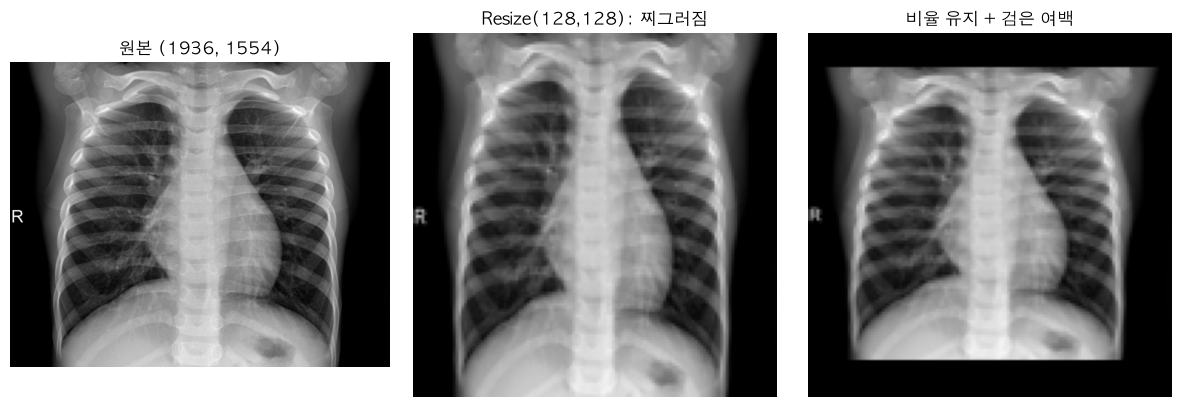

예측이 바뀐 test 이미지 수: 172 / 624
       학습 데이터 (실제)  test 예측: Resize  test 예측: 비율 유지
정상(0)        0.257            0.423           0.151
폐렴(1)        0.743            0.577           0.849


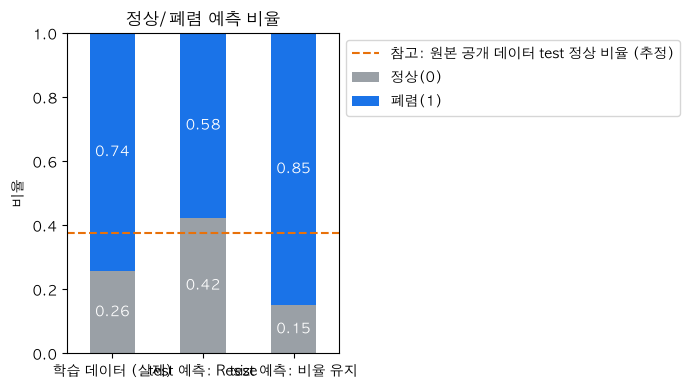

In [26]:
# 3-5) 입력 형태 일치 효과 확인

# ① 같은 test 이미지를 두 방식으로 변환해 비교
test_names = pd.read_csv(TEST_CSV)["file_name"].tolist()
sample_img = Image.open(os.path.join(TEST_DIR, test_names[0])).convert("L")

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(sample_img, cmap='gray'); axes[0].set_title(f"원본 {sample_img.size}")
axes[1].imshow(sample_img.resize((128, 128)), cmap='gray'); axes[1].set_title("Resize(128,128): 찌그러짐")
axes[2].imshow(resize_with_padding(sample_img, 128), cmap='gray'); axes[2].set_title("비율 유지 + 검은 여백")
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

# ② 같은 모델(cnn)로 test를 두 방식으로 예측해 분포 비교
preds_resize = predict_test(cnn, make_test_loader(tf))
preds_pad    = predict_test(cnn, make_test_loader(tf_cnn_pad))
print("예측이 바뀐 test 이미지 수:", (preds_resize != preds_pad).sum(), "/", len(preds_pad))

ratio = pd.DataFrame({
    '학습 데이터 (실제)': pd.Series(labels).value_counts(normalize=True).sort_index(),
    'test 예측: Resize': pd.Series(preds_resize).value_counts(normalize=True).reindex([0, 1], fill_value=0),
    'test 예측: 비율 유지': pd.Series(preds_pad).value_counts(normalize=True).reindex([0, 1], fill_value=0),
})
ratio.index = ['정상(0)', '폐렴(1)']
print(ratio.round(3))

ax = ratio.T.plot(kind='bar', stacked=True, figsize=(7, 4), color=['#9AA0A6', '#1A73E8'])
ax.axhline(0.375, color='#E8710A', linestyle='--', label='참고: 원본 공개 데이터 test 정상 비율 (추정)')
ax.set_ylim(0, 1); ax.set_ylabel('비율'); ax.set_title('정상/폐렴 예측 비율')
ax.tick_params(axis='x', rotation=0)
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', label_type='center', color='white')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

### Mission 3 결과

**1) Baseline 검증 성능 (SimpleCNN, 검증 데이터 1,044장)**

| 기준 | Accuracy | 민감도 | 특이도 | F1 | AUC |
|---|---|---|---|---|---|
| 학습 데이터 기준 (Mission 1) | 0.985 | 0.992 | 0.965 | 0.990 | 0.999 |
| **검증 데이터 기준 (Baseline 점수)** | **0.962** | **0.960** | **0.966** | **0.974** | **0.993** |

- 학습 데이터 기준보다 Accuracy가 약 2.3%p 낮아졌다. 학습 데이터를 일부 외운 효과(과적합)가 있었지만 정도는 크지 않다.
- 최적 epoch는 8이었고, 이후 val loss가 다시 올라가기 시작했다 → 검증 loss 기준 모델 저장이 필요한 이유.
- 혼동행렬 기준 오진: 정상 → 폐렴 약 9장(268장 중), 폐렴 → 정상 약 31장(776장 중).
  임상적으로 더 위험한 **위음성(폐렴을 놓침)이 더 많다**는 점이 Baseline의 한계이다.

**2) 입력 형태 일치 (비율 유지 리사이즈)**

| | test 정상 예측 비율 | test 폐렴 예측 비율 |
|---|---|---|
| Resize(128,128) (찌그러짐) | 0.423 | 0.577 |
| 비율 유지 + 검은 여백 | 0.151 | 0.849 |

- 전처리만 바꿨는데 test 624장 중 **172장(27.6%)의 예측이 바뀌었다**. 모델이 입력 형태에 크게 민감하다는 뜻이다.
- 다만 정상 예측 비율이 참고값(원본 공개 데이터 test의 정상 비율 약 37.5%, 추정)에서 오히려 **멀어졌다**. 가설(학습 때와 같은 형태로 넣으면 예측이 정확해질 것)은 이 결과로는 **지지되지 않았다**.
- 가능한 원인
    - train 이미지가 어떤 방법(보간 방식, 여백 처리)으로 224로 가공되었는지 알 수 없어, 우리가 만든 여백 방식이 실제 train과 완전히 같지 않을 수 있다.
    - 모델이 폐 음영보다 **여백의 크기와 위치** 같은 단서를 함께 학습했을 가능성 → Mission 5의 Grad-CAM으로 확인
- test에는 정답이 없어 어느 전처리가 더 정확한지 직접 확인할 수 없다는 한계가 있다.
  train과 같은 형태를 유지한다는 원칙에 따라 이후 실험은 비율 유지 전처리를 사용했다.

# Mission 4. ResNet50 개선 실험

## 1. 문제 정의
- **과제 규칙**: 사전학습 모델을 쓸 때는 단순 모델 변경 외에 **개선 전략 2개 이상**을 적용하고, Baseline 대비 성능을 비교해야 한다.
- **Mission 2에서 확인한 ResNet50 전이학습의 한계**
    - 분류층만 학습해 train loss가 0.12 근처에서 정체 → ImageNet(일상 사진)과 X-ray의 차이(도메인 차이)
    - 특이도 0.913으로 민감도(0.988)보다 낮고, test의 73%를 폐렴으로 예측 → 클래스 불균형(폐렴 74%)의 영향

## 2. 전체 흐름 (한 번에 하나씩 추가)
| 실험 | 변경 | 가설 |
|---|---|---|
| R0 | ResNet50 전이학습 (백본 고정) + 비율 유지 입력 | 개선 실험의 출발점 |
| R1 | R0 + **class weight** | 손실 계산에서 정상(소수 클래스)의 비중을 높이면 특이도가 개선될 것이다 |
| R2 | R1 + **Fine-tuning** (layer4 학습) | 고수준 특징을 X-ray에 맞게 조정하면 전반적인 성능이 오를 것이다 |
| R3 | R2 + **데이터 증강** (학습 데이터에만) | 다양한 형태를 학습해 과적합이 줄고 일반화가 좋아질 것이다 |

- **Fine-tuning 설정과 근거**
    - layer1 ~ layer3 **고정**: 경계선, 질감 같은 일반적인 특징은 X-ray에도 쓸 수 있으므로 보존
    - layer4 + fc **학습**: 고수준 특징(어떤 모양이 무엇을 뜻하는가)은 일상 사진과 X-ray가 달라 다시 학습
    - 학습률: layer4는 **1e-4**(사전학습 가중치를 크게 흔들지 않도록 낮게), fc는 1e-3
    - 전체를 풀지 않은 이유: 학습 데이터가 약 4천 장으로 적어 2,350만 개 전체를 학습하면 과적합 위험이 큼
- **데이터 증강**: ±10° 회전, 밝기·대비 변화 (원본 데이터에 회전된 영상이 있음). 좌우 반전은 심장 위치가 바뀌어 제외
- 모든 실험은 같은 분할, 같은 epoch, 검증 loss 최저 epoch의 모델로 평가한다.

In [27]:
# 4-0) 실험 준비

# ResNet50 생성 함수: finetune=True이면 layer4도 학습
def build_resnet(finetune=False):
    torch.manual_seed(42)
    m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    for p in m.parameters():
        p.requires_grad = False                     # 전체 고정
    if finetune:
        for p in m.layer4.parameters():
            p.requires_grad = True                  # layer4만 학습
    m.fc = nn.Linear(m.fc.in_features, 2)           # 분류층 교체 (항상 학습)
    m = m.to(device)
    n = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f"학습 파라미터: {n:,}")
    return m

# class weight: 학습 데이터 개수의 역수에 비례 → 적은 클래스(정상)에 더 큰 가중치
counts = np.bincount([labels[i] for i in tr_idx])
class_w = torch.tensor(len(tr_idx) / (2 * counts), dtype=torch.float32).to(device)
print("학습 데이터 개수 (정상, 폐렴):", counts, "→ class weight:", class_w.cpu().numpy().round(3))

ce_plain  = nn.CrossEntropyLoss()
ce_weight = nn.CrossEntropyLoss(weight=class_w)

# 데이터로더: 증강 없음 / 학습 데이터에만 증강
res_train_loader, res_val_loader = make_loaders(tf_res_pad, tf_res_pad)
aug_train_loader, _              = make_loaders(tf_res_aug, tf_res_pad)

학습 데이터 개수 (정상, 폐렴): [1073 3099] → class weight: [1.944 0.673]


학습 파라미터: 4,098
Epoch  1 | train loss 0.2278 | val loss 0.1410
Epoch  2 | train loss 0.1675 | val loss 0.1386
Epoch  3 | train loss 0.1486 | val loss 0.1149
Epoch  4 | train loss 0.1526 | val loss 0.1171
Epoch  5 | train loss 0.1348 | val loss 0.1404
Epoch  6 | train loss 0.1353 | val loss 0.1119
Epoch  7 | train loss 0.1139 | val loss 0.1036
Epoch  8 | train loss 0.1122 | val loss 0.1018
Epoch  9 | train loss 0.1105 | val loss 0.0989
Epoch 10 | train loss 0.1021 | val loss 0.0946
→ 최적 epoch: 10 (val loss 0.0946)


/var/folders/bd/mmvg00pj33n_skzfx2sf9tt00000gn/T/ipykernel_39915/1508372954.py:57: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  y_true.extend(np.array(y))


===== R0 전이학습 (검증 데이터) =====
Accuracy: 0.9693
민감도     : 0.9794
특이도     : 0.9403
F1      : 0.9794
AUC     : 0.9924


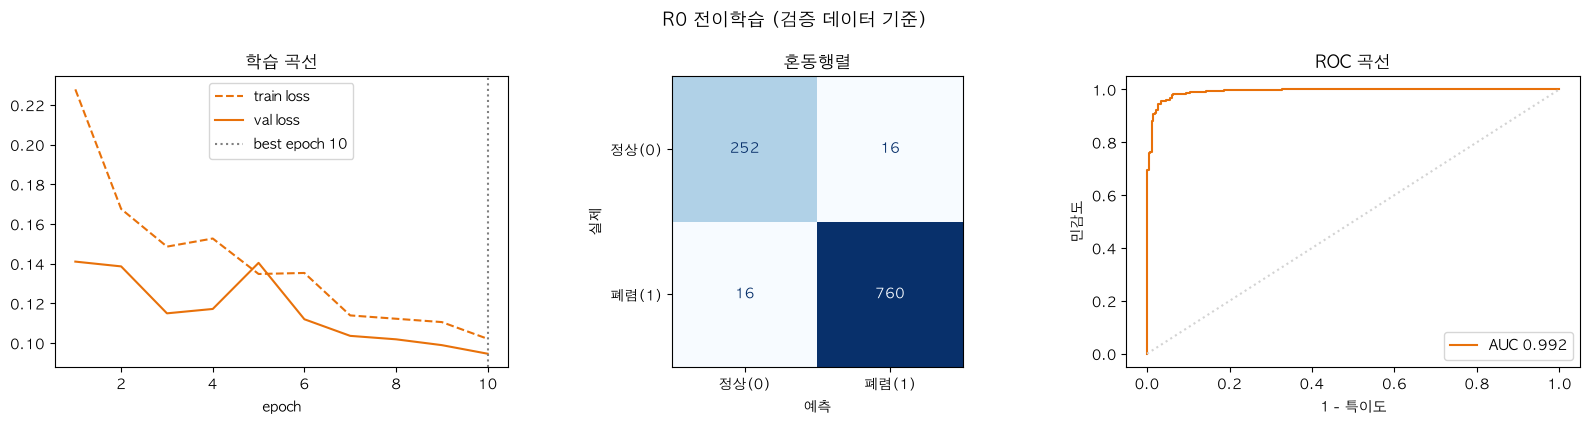

{'Accuracy': 0.9693486590038314,
 '민감도': np.float64(0.979381443298969),
 '특이도': np.float64(0.9402985074626866),
 'F1': 0.979381443298969,
 'AUC': 0.9924459532235728}

In [28]:
# 4-1) R0: ResNet50 전이학습 (백본 고정)
r0 = build_resnet(finetune=False)
r0_hist = train_model(r0, res_train_loader, res_val_loader,
                      optim.Adam(r0.fc.parameters(), lr=0.001), ce_plain)
record('R0 전이학습', r0, res_val_loader, r0_hist, eval_tf=tf_res_pad, color='#E8710A')

학습 파라미터: 4,098
Epoch  1 | train loss 0.2625 | val loss 0.1703
Epoch  2 | train loss 0.1858 | val loss 0.1559
Epoch  3 | train loss 0.1652 | val loss 0.2111
Epoch  4 | train loss 0.1645 | val loss 0.1341
Epoch  5 | train loss 0.1497 | val loss 0.1247
Epoch  6 | train loss 0.1373 | val loss 0.2355
Epoch  7 | train loss 0.1430 | val loss 0.1508
Epoch  8 | train loss 0.1363 | val loss 0.1446
Epoch  9 | train loss 0.1388 | val loss 0.1234
Epoch 10 | train loss 0.1333 | val loss 0.1137
→ 최적 epoch: 10 (val loss 0.1137)


/var/folders/bd/mmvg00pj33n_skzfx2sf9tt00000gn/T/ipykernel_39915/1508372954.py:57: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  y_true.extend(np.array(y))


===== R1 +class weight (검증 데이터) =====
Accuracy: 0.9531
민감도     : 0.9549
특이도     : 0.9478
F1      : 0.9680
AUC     : 0.9921


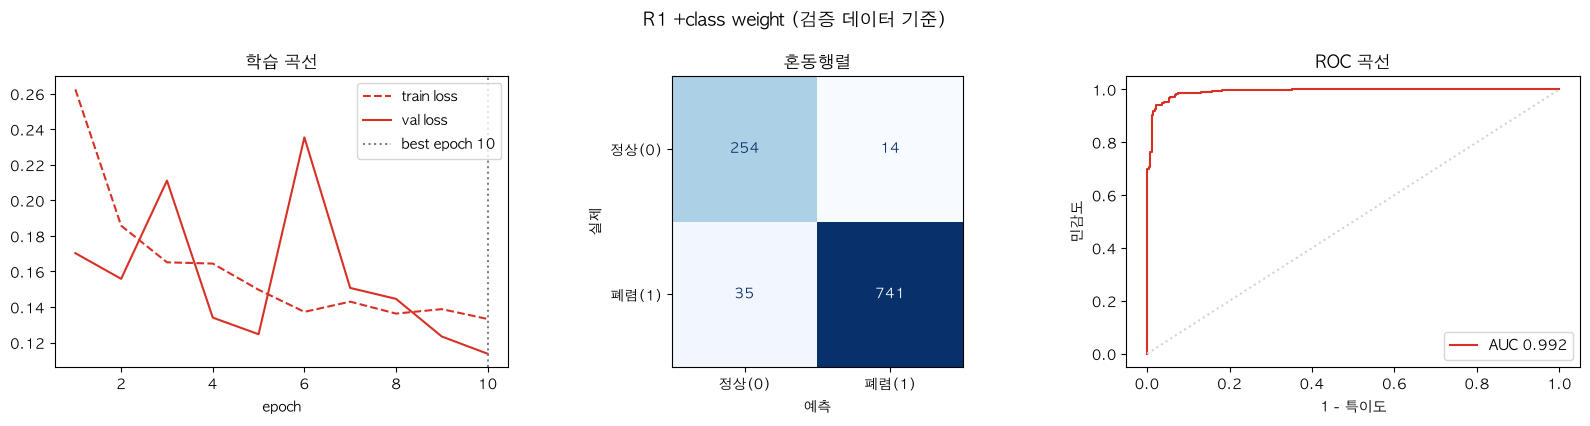

{'Accuracy': 0.9530651340996169,
 '민감도': np.float64(0.9548969072164949),
 '특이도': np.float64(0.9477611940298507),
 'F1': 0.9679947746570868,
 'AUC': 0.9920612786582551}

In [29]:
# 4-2) R1: R0 + class weight
r1 = build_resnet(finetune=False)
r1_hist = train_model(r1, res_train_loader, res_val_loader,
                      optim.Adam(r1.fc.parameters(), lr=0.001), ce_weight)
record('R1 +class weight', r1, res_val_loader, r1_hist, eval_tf=tf_res_pad, color='#D93025')

학습 파라미터: 14,968,834
Epoch  1 | train loss 0.1326 | val loss 0.0796
Epoch  2 | train loss 0.0365 | val loss 0.0578
Epoch  3 | train loss 0.0186 | val loss 0.0906
Epoch  4 | train loss 0.0156 | val loss 0.1239
Epoch  5 | train loss 0.0275 | val loss 0.1192
Epoch  6 | train loss 0.0149 | val loss 0.1004
Epoch  7 | train loss 0.0021 | val loss 0.0758
Epoch  8 | train loss 0.0003 | val loss 0.0851
Epoch  9 | train loss 0.0028 | val loss 0.0951
Epoch 10 | train loss 0.0124 | val loss 0.0770
→ 최적 epoch: 2 (val loss 0.0578)


/var/folders/bd/mmvg00pj33n_skzfx2sf9tt00000gn/T/ipykernel_39915/1508372954.py:57: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  y_true.extend(np.array(y))


===== R2 +Fine-tuning (검증 데이터) =====
Accuracy: 0.9770
민감도     : 0.9742
특이도     : 0.9851
F1      : 0.9844
AUC     : 0.9982


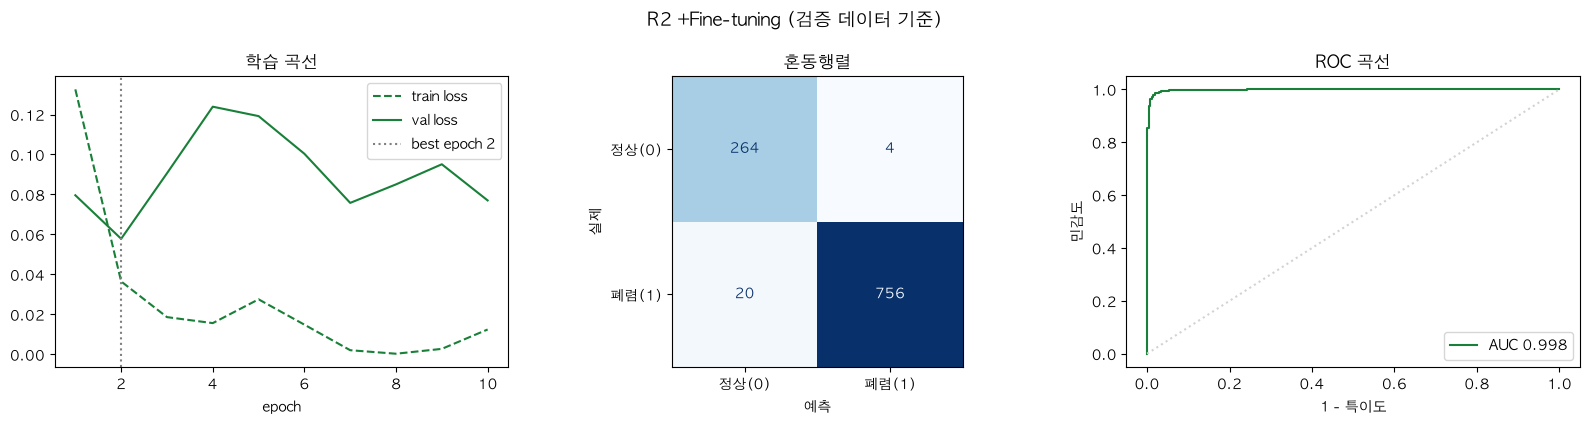

{'Accuracy': 0.9770114942528736,
 '민감도': np.float64(0.9742268041237113),
 '특이도': np.float64(0.9850746268656716),
 'F1': 0.984375,
 'AUC': 0.9981824126788736}

In [30]:
# 4-3) R2: R1 + Fine-tuning (layer4)
r2 = build_resnet(finetune=True)
r2_opt = optim.Adam([
    {'params': r2.layer4.parameters(), 'lr': 1e-4},   # 사전학습 층: 낮은 학습률
    {'params': r2.fc.parameters(),     'lr': 1e-3},   # 새 분류층: 기본 학습률
])
r2_hist = train_model(r2, res_train_loader, res_val_loader, r2_opt, ce_weight)
record('R2 +Fine-tuning', r2, res_val_loader, r2_hist, eval_tf=tf_res_pad, color='#188038')

학습 파라미터: 14,968,834
Epoch  1 | train loss 0.1490 | val loss 0.0879
Epoch  2 | train loss 0.0836 | val loss 0.0851
Epoch  3 | train loss 0.0709 | val loss 0.1419
Epoch  4 | train loss 0.0449 | val loss 0.0765
Epoch  5 | train loss 0.0413 | val loss 0.0814
Epoch  6 | train loss 0.0373 | val loss 0.0675
Epoch  7 | train loss 0.0290 | val loss 0.0798
Epoch  8 | train loss 0.0181 | val loss 0.0743
Epoch  9 | train loss 0.0291 | val loss 0.0840
Epoch 10 | train loss 0.0257 | val loss 0.0832
→ 최적 epoch: 6 (val loss 0.0675)


/var/folders/bd/mmvg00pj33n_skzfx2sf9tt00000gn/T/ipykernel_39915/1508372954.py:57: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  y_true.extend(np.array(y))


===== R3 +증강 (검증 데이터) =====
Accuracy: 0.9770
민감도     : 0.9768
특이도     : 0.9776
F1      : 0.9844
AUC     : 0.9976


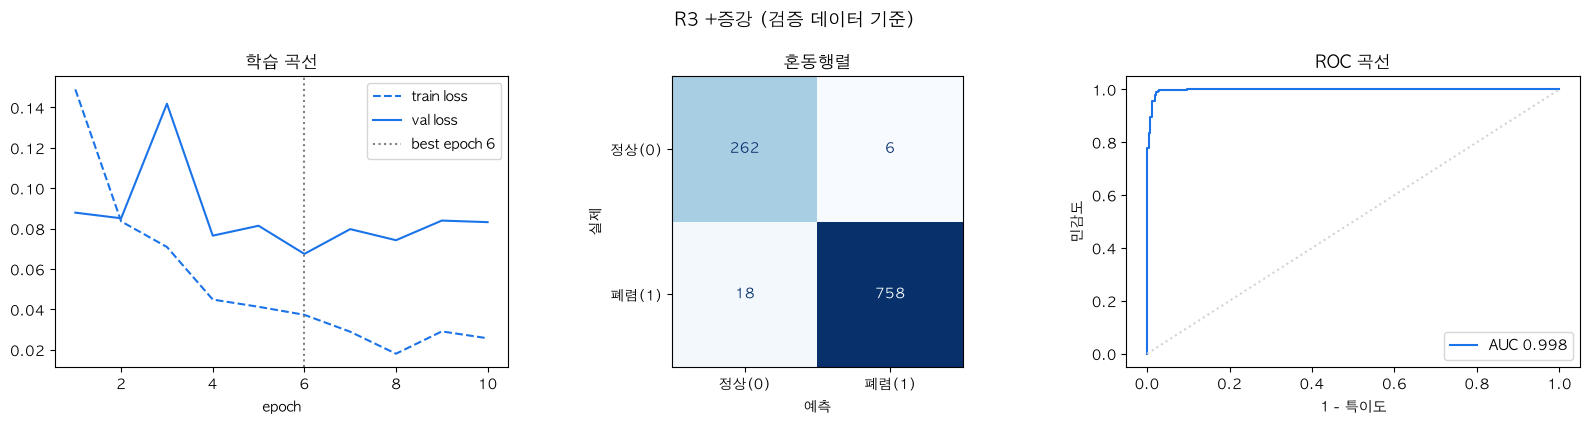

{'Accuracy': 0.9770114942528736,
 '민감도': np.float64(0.9768041237113402),
 '특이도': np.float64(0.9776119402985075),
 'F1': 0.9844155844155844,
 'AUC': 0.9975765502384982}

In [31]:
# 4-4) R3: R2 + 데이터 증강 (학습 데이터에만 적용, 검증은 원본 그대로)
r3 = build_resnet(finetune=True)
r3_opt = optim.Adam([
    {'params': r3.layer4.parameters(), 'lr': 1e-4},
    {'params': r3.fc.parameters(),     'lr': 1e-3},
])
r3_hist = train_model(r3, aug_train_loader, res_val_loader, r3_opt, ce_weight)
record('R3 +증강', r3, res_val_loader, r3_hist, eval_tf=tf_res_pad, color='#1A73E8')

### Mission 4 결과

| 실험 | Accuracy | 민감도 | 특이도 | F1 | AUC | best epoch | 직전 실험 대비 |
|---|---|---|---|---|---|---|---|
| (참고) SimpleCNN Baseline | 0.962 | 0.960 | 0.966 | 0.974 | 0.993 | 8 | - |
| R0 전이학습 | 0.969 | 0.979 | 0.940 | 0.979 | 0.992 | 10 | Baseline 대비 Accuracy +0.8%p, 특이도 -2.6%p |
| R1 +class weight | 0.953 | 0.955 | 0.948 | 0.968 | 0.992 | 10 | 특이도 +0.7%p, 민감도 -2.4%p, Accuracy -1.6%p |
| R2 +Fine-tuning | **0.977** | 0.974 | **0.985** | **0.984** | **0.998** | 2 | Accuracy +2.4%p, 특이도 +3.7%p |
| R3 +증강 | **0.977** | **0.977** | 0.978 | **0.984** | 0.998 | 6 | Accuracy 동일, 민감도 +0.3%p, 특이도 -0.7%p |

**R0 전이학습 (백본 고정)**
- Baseline보다 Accuracy는 조금 올랐지만, 민감도만 오르고 특이도는 0.940으로 떨어졌다 → 폐렴 쪽으로 치우친 예측.
- 분류층(4,098개)만 학습해 train loss가 0.10 아래로 내려가지 않았다. ImageNet 특징만으로는 X-ray의 미세한 차이를 충분히 구분하지 못한다.

**R1 +class weight → 가설 일부만 맞음**
- 특이도는 0.940 → 0.948로 소폭 올랐지만(정상 약 2장 더 맞힘), 민감도가 0.979 → 0.955로 더 크게 떨어져 Accuracy가 낮아졌다.
- AUC는 0.992로 거의 같다. 구분 능력 자체는 그대로이고, **판정 기준을 정상 쪽으로 옮긴 효과**만 있었다는 뜻이다.
- val loss가 epoch마다 크게 흔들렸다(0.21, 0.24). 가중치가 큰 정상 샘플 몇 장에 손실이 크게 좌우되어 학습이 불안정해진 것으로 보인다.
- 배운 점: 백본이 고정된 상태에서는 불균형 보정만으로 성능을 올리기 어렵다. 특징 자체를 개선해야 한다.

**R2 +Fine-tuning → 가설 맞음, 가장 큰 개선**
- Accuracy 0.977, 특이도 0.985, AUC 0.998로 모든 지표가 크게 올랐다. layer4를 X-ray에 맞게 다시 학습한 효과가 확인되었다.
- 다만 학습 파라미터가 약 1,500만 개로 늘어 **과적합이 빠르게 진행**되었다. 최적 epoch는 2였고, 이후 train loss는 0.0003까지 떨어졌지만 val loss는 다시 올랐다.
  검증 loss 기준으로 모델을 저장하지 않았다면 과적합된 마지막 epoch 모델을 썼을 것이다.

**R3 +데이터 증강 → 가설 일부 맞음**
- 검증 Accuracy는 R2와 같았다(1,044장 중 1,020장 정답).
- 과적합은 줄었다: train loss가 0.02 ~ 0.04 수준을 유지했고, 최적 epoch가 2 → 6으로 늦춰졌으며 val loss의 흔들림도 작아졌다.
- 민감도는 0.974 → 0.977로 소폭 올랐고(폐렴을 놓친 수 약 20장 → 18장), 특이도는 0.985 → 0.978로 소폭 내려갔다.
  검증 데이터에서 몇 장 차이라 우연에 의한 차이일 가능성도 있다.

# Mission 5. 결과 비교 해석과 최종 모델 선정

## 1. 문제 정의
- Mission 3, 4의 모든 실험을 **같은 검증 데이터**로 비교해 어떤 전략이 효과가 있었는지 해석한다.
- 검증 성능이 가장 좋은 모델을 최종 모델로 선정해 test를 예측하고 제출한다.
- 모델이 실제로 **폐 영역을 보고 판단하는지** Grad-CAM으로 확인한다 (여백, R 표시, 전극선을 단서로 쓰는지 점검).

## 2. 전체 흐름
1) 전체 실험 비교표, 지표 막대그래프, ROC 곡선, 검증 loss 곡선
2) 최종 모델 선정: 주 지표인 **검증 Accuracy**가 가장 높은 모델 (민감도, 특이도도 함께 확인)
3) Grad-CAM: 정상 정답, 폐렴 정답, 오분류 예시에서 모델이 주목한 영역 확인
4) 최종 모델로 test 예측 → `final_submit.csv`
5) 재현성 확인: 커널 재시작 → Run All 후 같은 결과가 나오는지 확인

,Accuracy,민감도,특이도,F1,AUC,best epoch,Accuracy 변화 (Baseline 대비)
SimpleCNN (Baseline),0.9617,0.9601,0.9664,0.9739,0.9933,8,0.0000
R0 전이학습,0.9693,0.9794,0.9403,0.9794,0.9924,10,0.0076
R1 +class weight,0.9531,0.9549,0.9478,0.9680,0.9921,10,-0.0086
R2 +Fine-tuning,0.9770,0.9742,0.9851,0.9844,0.9982,2,0.0153
R3 +증강,0.9770,0.9768,0.9776,0.9844,0.9976,6,0.0153


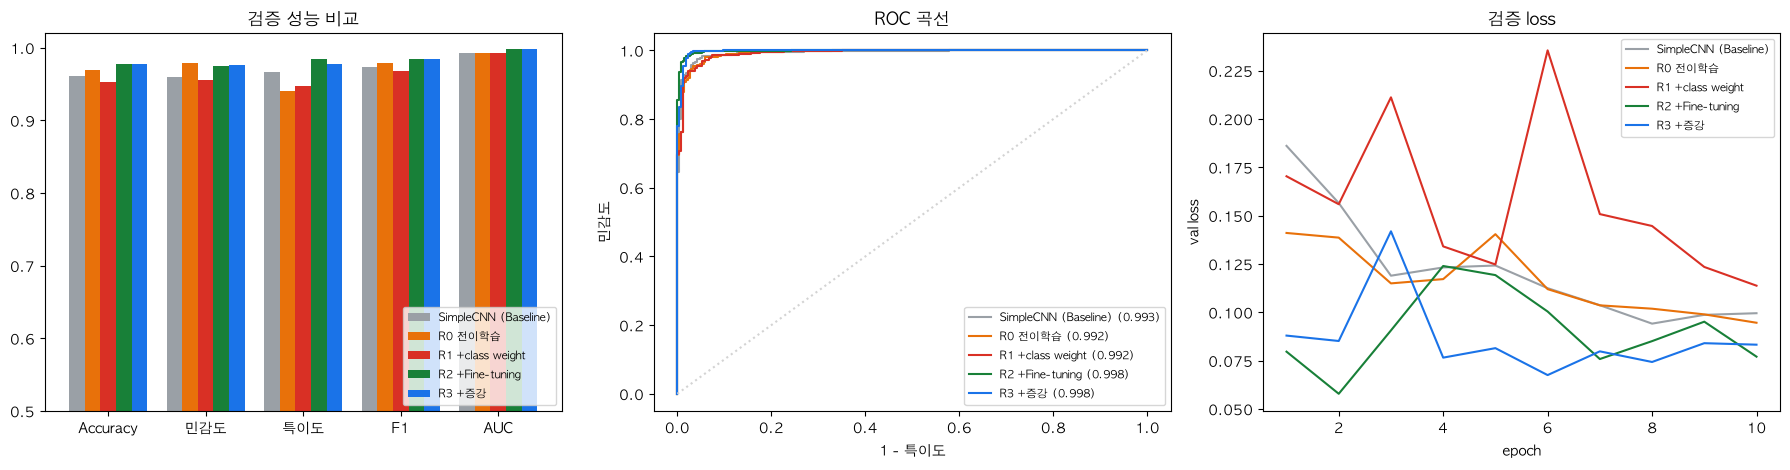

In [32]:
# 5-1) 전체 실험 비교
result_df = pd.DataFrame(results).T.round(4)
result_df['best epoch'] = [histories[n]['best_epoch'] for n in result_df.index]
base = result_df.iloc[0]
result_df['Accuracy 변화 (Baseline 대비)'] = (result_df['Accuracy'] - base['Accuracy']).round(4)
display(result_df)

palette = ['#9AA0A6', '#E8710A', '#D93025', '#188038', '#1A73E8']
names = list(results.keys())

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# ① 지표 막대그래프
pd.DataFrame(results).loc[['Accuracy', '민감도', '특이도', 'F1', 'AUC']].plot(
    kind='bar', ax=axes[0], color=palette[:len(names)], width=0.8)
axes[0].set_ylim(0.5, 1.02); axes[0].set_title('검증 성능 비교')
axes[0].tick_params(axis='x', rotation=0); axes[0].legend(fontsize=8, loc='lower right')

# ② ROC 곡선
for n, c in zip(names, palette):
    y_true, _, y_prob = outputs[n]
    fpr, tpr, _ = metrics.roc_curve(y_true, y_prob)
    axes[1].plot(fpr, tpr, color=c, label=f"{n} ({results[n]['AUC']:.3f})")
axes[1].plot([0, 1], [0, 1], color='lightgray', linestyle=':')
axes[1].set_xlabel('1 - 특이도'); axes[1].set_ylabel('민감도'); axes[1].set_title('ROC 곡선')
axes[1].legend(fontsize=8, loc='lower right')

# ③ 검증 loss 곡선 (모델마다 loss 크기가 달라 경향만 비교)
for n, c in zip(names, palette):
    axes[2].plot(range(1, len(histories[n]['val']) + 1), histories[n]['val'], color=c, label=n)
axes[2].set_xlabel('epoch'); axes[2].set_ylabel('val loss'); axes[2].set_title('검증 loss')
axes[2].legend(fontsize=8)

plt.tight_layout(); plt.show()

In [33]:
# 5-2) 최종 모델 선정 (검증 Accuracy 최고)
best_name = result_df['Accuracy'].idxmax()
final_model = trained[best_name]
print("최종 모델:", best_name)
print(result_df.loc[best_name, ['Accuracy', '민감도', '특이도', 'F1', 'AUC']])

최종 모델: R2 +Fine-tuning
Accuracy    0.9770
민감도         0.9742
특이도         0.9851
F1          0.9844
AUC         0.9982
Name: R2 +Fine-tuning, dtype: float64


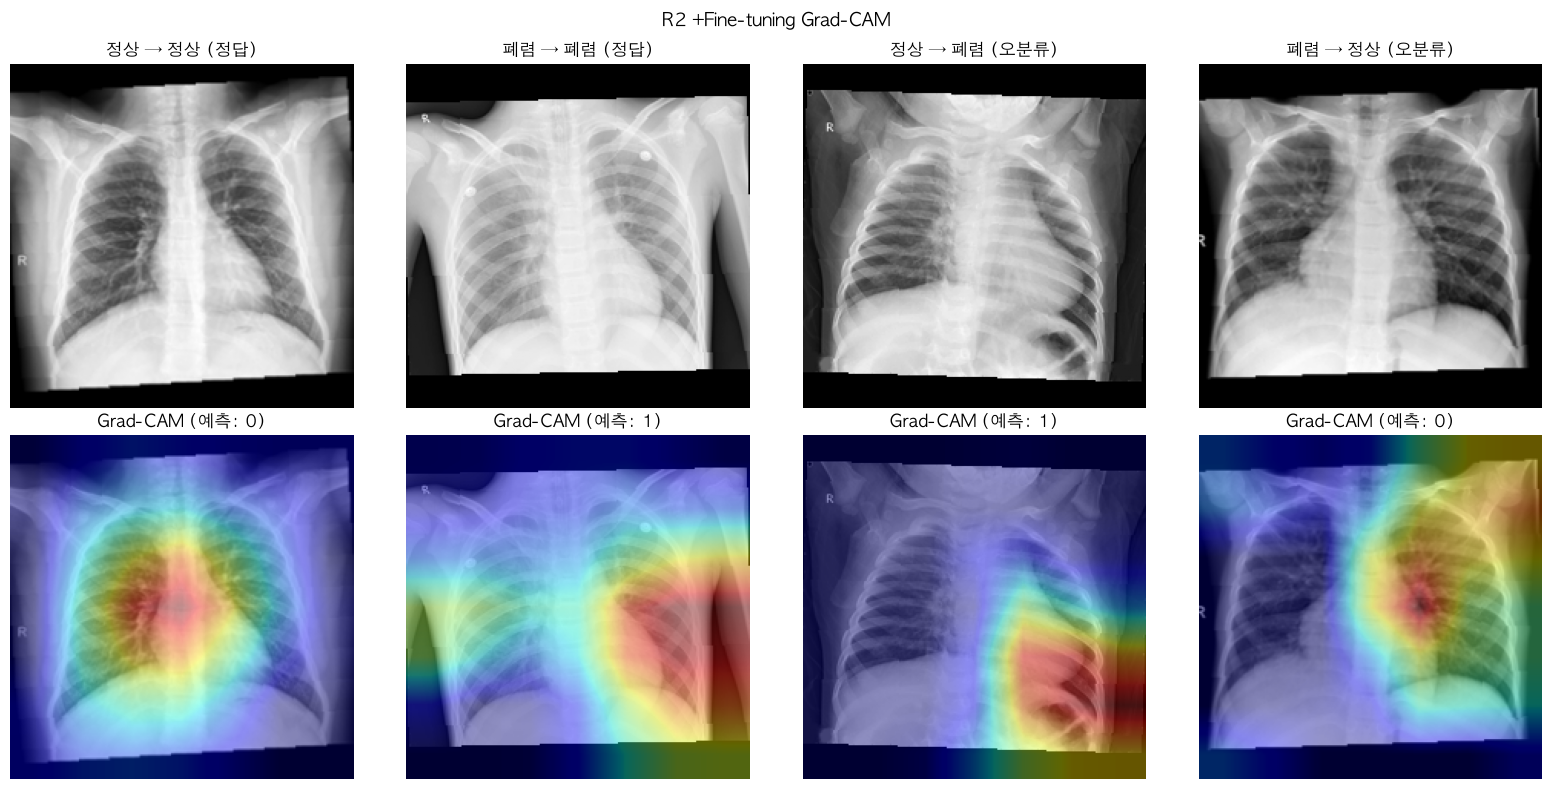

In [34]:
# 5-3) Grad-CAM: 모델이 어디를 보고 판단했는지 확인
def grad_cam(model, x):
    target = model.layer4 if hasattr(model, 'layer4') else model.conv[3]   # 마지막 합성곱 층
    store = {}
    def fwd_hook(m, i, o):
        store['feat'] = o
        o.register_hook(lambda g: store.__setitem__('grad', g))
    h = target.register_forward_hook(fwd_hook)
    model.eval()
    x = x.unsqueeze(0).to(device).requires_grad_(True)
    out = model(x)
    cls = out.argmax(1).item()
    model.zero_grad(); out[0, cls].backward()
    h.remove()
    w = store['grad'].mean(dim=(2, 3), keepdim=True)                       # 채널별 중요도
    cam = torch.relu((w * store['feat']).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[0, 0]
    cam = (cam / (cam.max() + 1e-8)).detach().cpu().numpy()
    return cam, cls

# 검증 데이터에서 예시 고르기: 정상 정답, 폐렴 정답, 오분류
cam_ds = TrainCSV(TRAIN_CSV, root_dir=TRAIN_DIR); cam_ds.tf = eval_tfs[best_name]
y_true, y_pred, _ = outputs[best_name]
picks = []
for cond, title in [((y_true == 0) & (y_pred == 0), '정상 → 정상 (정답)'),
                    ((y_true == 1) & (y_pred == 1), '폐렴 → 폐렴 (정답)'),
                    ((y_true == 0) & (y_pred == 1), '정상 → 폐렴 (오분류)'),
                    ((y_true == 1) & (y_pred == 0), '폐렴 → 정상 (오분류)')]:
    pos = np.where(cond)[0]
    if len(pos):
        picks.append((va_idx[pos[0]], title))

fig, axes = plt.subplots(2, len(picks), figsize=(4 * len(picks), 8))
for col, (idx, title) in enumerate(picks):
    x, y = cam_ds[idx]
    cam, cls = grad_cam(final_model, x)
    img = x[0].numpy(); img = (img - img.min()) / (img.max() - img.min() + 1e-8)
    axes[0, col].imshow(img, cmap='gray'); axes[0, col].set_title(title)
    axes[1, col].imshow(img, cmap='gray'); axes[1, col].imshow(cam, cmap='jet', alpha=0.4)
    axes[1, col].set_title(f'Grad-CAM (예측: {cls})')
    axes[0, col].axis('off'); axes[1, col].axis('off')
plt.suptitle(f'{best_name} Grad-CAM', fontsize=13)
plt.tight_layout(); plt.show()

In [35]:
# 5-4) 최종 모델로 test 예측 및 제출
final_preds = predict_test(final_model, make_test_loader(eval_tfs[best_name]))

submission = pd.read_csv(SUBMIT_CSV)
submission["label"] = final_preds
submission.to_csv("final_submit.csv", index=False)
print("최종 모델:", best_name)
print(submission["label"].value_counts())

최종 모델: R2 +Fine-tuning
label
1    484
0    140
Name: count, dtype: int64


### Mission 5 결과 해석

**1) 최종 모델: R2 +Fine-tuning**
- 검증 Accuracy 0.977, 민감도 0.974, 특이도 0.985, F1 0.984, AUC 0.998
- Baseline(SimpleCNN) 대비 Accuracy **+1.5%p**, 특이도 +1.9%p, 민감도 +1.4%p, AUC +0.005
- R2와 R3의 검증 Accuracy가 같아(1,020/1,044), 코드는 표에서 먼저 나온 R2를 선택했다.
    - R2: 특이도와 AUC가 더 높음
    - R3: 민감도가 더 높고(위음성 18장 vs 20장), 과적합이 덜함
    - 문제 정의에서 위음성을 더 위험하다고 보았으므로, **임상적 우선순위를 기준으로 하면 R3을 선택하는 것도 타당**하다. 두 모델의 차이는 검증 데이터 몇 장 수준이다.

**2) 전략별 효과**
| 전략 | 가설 | 결과 | 해석 |
|---|---|---|---|
| 평가 체계 (검증 분할) | 학습 데이터 점수는 실제보다 높다 | Accuracy 0.985 → 0.962 | 공정한 비교의 기준을 마련함 |
| 입력 형태 일치 | test를 학습 때와 같은 형태로 입력 | 172장 예측 변화, 정상 예측 0.423 → 0.151 | 모델이 입력 형태에 민감함을 확인. 정답이 없어 효과는 확인하지 못함 |
| 전이학습 (R0) | 사전학습 특징이 적은 데이터에서 유리 | Accuracy +0.8%p, 특이도 -2.6%p | 백본 고정만으로는 효과가 작음 |
| class weight (R1) | 특이도 개선 | 특이도 +0.7%p, Accuracy -1.6%p | 판정 기준만 이동, 구분 능력(AUC)은 그대로 |
| Fine-tuning (R2) | 도메인 차이 극복 | Accuracy +2.4%p, 특이도 +3.7%p | **가장 효과가 큰 전략** |
| 데이터 증강 (R3) | 과적합 감소 | Accuracy 동일, 최적 epoch 2 → 6 | 과적합은 줄었지만 점수 향상은 없음 |

**3) Grad-CAM 확인 (R2)**
- **폐렴 → 폐렴 (정답)**: 한쪽 폐의 하엽 쪽 음영이 증가한 부위에 주목했다. 폐렴 소견이 있는 폐야를 근거로 판단한 것으로 보인다.
- **정상 → 정상 (정답)**: 양쪽 폐보다는 영상 중앙(종격동, 심장 부위)에 주목했다. 정상 판단의 근거가 폐야인지는 분명하지 않다.
- **정상 → 폐렴 (오분류)**: 심장 옆 하엽과 횡격막 부근에 주목했다. 회전된 영상이라 이 부위가 하얗게 겹쳐 보여 음영으로 오인했을 가능성이 있다.
- **폐렴 → 정상 (오분류)**: 한쪽 상엽과 함께 **영상 바깥의 검은 여백(오른쪽 위 모서리)**에도 주목했다.
- 일부 예시에서 아래쪽 여백까지 주목 영역이 넓게 퍼져 있었다. 모델이 폐 음영 외에 **여백 같은 영상 외 정보도 일부 사용**하고 있을 가능성이 있다.
  (layer4의 Grad-CAM은 7×7 크기를 확대한 것이라 위치 해상도가 낮다는 한계도 있다.)

**4) 최종 제출**
- `final_submit.csv`: test 624장 중 정상 140장(22.4%), 폐렴 484장(77.6%)으로 예측
- 검증 데이터에서는 특이도가 0.985로 높았지만, test에서는 정상 예측 비율이 참고값(약 37.5%, 추정)보다 낮다.
  train(미리 가공된 이미지)과 test(원본 이미지)의 차이 때문에 **검증 성능이 test에서 그대로 나오지 않을 수 있다**.

**5) 한계와 배운 점**
- **배운 점**
    - 학습 데이터로 평가하면 성능이 실제보다 좋아 보인다. 검증 데이터를 따로 두어야 전략의 효과를 공정하게 비교할 수 있다.
    - 사전학습 모델은 그대로 쓰는 것보다 **일부 층을 데이터에 맞게 다시 학습(Fine-tuning)**할 때 효과가 컸다.
    - 학습하는 파라미터가 많아질수록 과적합이 빨라져, 검증 loss 기준 모델 저장과 데이터 증강이 중요했다.
    - class weight처럼 효과가 기대와 달랐던 실험도, AUC를 함께 보면 "구분 능력이 아니라 판정 기준이 바뀌었다"는 원인을 알 수 있었다.
- **한계**
    - test에 정답이 없어 test 성능은 직접 확인할 수 없다. train과 test의 이미지 형태 차이가 가장 큰 남은 위험이다.
    - 원본 데이터는 한 환자의 영상이 여러 장일 수 있으나 파일명으로 환자를 구분할 수 없어, 검증 데이터에 같은 환자가 섞였을 가능성이 있다 (검증 점수가 실제보다 높을 수 있음).
    - Grad-CAM에서 여백에 주목하는 경우가 보였다. 폐 영역만 잘라 학습하거나(lung segmentation), 여백을 일정하게 맞추는 전처리를 다음 개선 방향으로 고려할 수 있다.
    - Mac GPU(mps)는 일부 연산이 완전히 결정적이지 않아, seed를 고정해도 소수점 아래 미세한 차이가 날 수 있다.